# 03 · Feature Engineering

**Objective:** turn cleaned event-level data into **one row per user** describing how each person used the app. Each feature is a hypothesis about what "effective engagement" means, and Steps 4–6 test those hypotheses.

**Design decisions**

| Decision | Choice | Rationale |
|---|---|---|
| Unit | One row per user | Retention and wellbeing outcomes are per user |
| Day definition | **Local calendar date**; day 0 = signup date | Matches how people experience days and streaks. Trade-off: day 0 is a partial day whose length depends on signup time |
| "Practice day" | ≥1 `practice_complete`, **or** a `practice_start` inside the iOS tracking gap (#12) | Completes weren't logged on iOS 5.2.0, Oct 5–12. Minutes use completes only (no minutes are invented) |
| Windows | **w1** = days 0–6 · **d0_27** = days 0–27 · weekly wk1–wk4 | A feature's window must end **before** the outcome it explains (no leakage) |
| No practices | Counts = 0; ratios = **NaN** + flag; categories = `none` | Zero would be a false statement for ratios |
| Small denominators | Content shares are NaN if < 3 practices | A share based on 1 practice is noise |
| Censoring | `d7_observable` / `d28_observable` flags; survival columns use duration + event flag | Users who signed up near the cutoff haven't had their full window |

**Feature groups:** A · Habit & volume · C · Content · D · Habit cues · E · Activation · F · Trajectory · G · Profile & wellbeing · Outcomes

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80); pd.set_option("display.width", 220)
PROC = Path("processed"); REPORTS = Path("reports"); REPORTS.mkdir(exist_ok=True)
CUTOFF = pd.Timestamp("2026-11-15 23:59:59", tz="UTC")

users       = pd.read_parquet(PROC / "users.parquet")
events      = pd.read_parquet(PROC / "events.parquet")
assessments = pd.read_parquet(PROC / "assessments.parquet")
experiment  = pd.read_parquet(PROC / "experiment.parquet")
content     = pd.read_parquet(PROC / "content.parquet")
print(users.shape, events.shape, assessments.shape, experiment.shape)

(15000, 13) (551903, 14) (15194, 36) (4416, 10)


---
## 1. Enrich events: local time and day number
Each event gets the user's **local** timestamp, **local hour** and **day number** (local calendar date minus local signup date).

In [2]:
tz = users.set_index("user_id").timezone
ev = events.copy()
ev["tz"] = ev.user_id.map(tz)

local_parts = []
for zone, idx in ev.groupby("tz").groups.items():
    local_parts.append(ev.loc[idx, "ts"].dt.tz_convert(zone).dt.tz_localize(None))
ev["local_ts"] = pd.concat(local_parts)

signup_local = pd.Series({uid: ts.tz_convert(z).tz_localize(None).normalize()
                          for uid, ts, z in zip(users.user_id, users.signup_ts, users.timezone)})
ev["day"] = (ev.local_ts.dt.normalize() - ev.user_id.map(signup_local)).dt.days
ev["local_hour"] = ev.local_ts.dt.hour

# how many days each user could be observed (local cutoff date - local signup date)
cutoff_local = pd.Series({uid: CUTOFF.tz_convert(z).tz_localize(None).normalize()
                          for uid, z in zip(users.user_id, users.timezone)})
obs_days = (cutoff_local - signup_local).dt.days

print(ev.day.describe())
assert (ev.day >= 0).all(), "events before signup date"

count    551903.000000
mean         27.834440
std          31.942719
min           0.000000
25%           2.000000
50%          16.000000
75%          42.000000
max         166.000000
Name: day, dtype: float64


In [3]:
def slot(h):
    return np.select([(h >= 5) & (h < 11), (h >= 11) & (h < 17)], ["morning", "midday"], "evening")

# Completed practices, with content info
comp = ev[ev.event_name == "practice_complete"].merge(content, on="content_id", how="left")
comp["minutes"] = comp.duration_sec / 60
comp["slot"] = slot(comp.local_hour)
comp["is_short"] = comp.duration_min <= 10

# Practice ACTIVITY (for day counts): completes + starts inside the iOS tracking gap (#12)
activity = pd.concat([
    ev.loc[ev.event_name == "practice_complete", ["user_id", "day"]],
    ev.loc[(ev.event_name == "practice_start") & ev.in_ios_tracking_gap, ["user_id", "day"]],
]).drop_duplicates()
print(f"completed practices: {len(comp):,} | practice user-days: {len(activity):,}")

completed practices: 136,838 | practice user-days: 107,185


---
## 2. Feature builders
Every feature starts from the full user list, so users with no activity are kept (with 0 / NaN / `none`).

In [4]:
F = users[["user_id"]].set_index("user_id")      # the feature table
U = F.index

def days_in(lo, hi):
    a = activity[activity.day.between(lo, hi)]
    return a.groupby("user_id").day.nunique().reindex(U, fill_value=0)

def comp_in(lo, hi):
    return comp[comp.day.between(lo, hi)]

def longest_streak(days):
    days = sorted(set(days)); best = cur = 0; prev = None
    for d in days:
        cur = cur + 1 if prev is not None and d == prev + 1 else 1
        best = max(best, cur); prev = d
    return best

### A · Habit & volume (week 1, days 0–6)

In [5]:
F["practice_days_w1"] = days_in(0, 6)
c1 = comp_in(0, 6)
F["minutes_w1"] = c1.groupby("user_id").minutes.sum().reindex(U, fill_value=0).round(1)
F["has_practice_w1"] = F.practice_days_w1 > 0
F["avg_minutes_per_practice_w1"] = c1.groupby("user_id").minutes.mean().reindex(U).round(1)   # NaN if none

a1 = activity[activity.day.between(0, 6)].sort_values(["user_id", "day"])
first2 = a1.groupby("user_id").day.apply(lambda s: list(s)[:2])
d2 = first2.map(lambda l: l[1] - l[0] if len(l) == 2 else np.nan)
F["had_second_practice_w1"] = d2.reindex(U).notna()
F["days_to_second_practice_w1"] = d2.reindex(U).fillna(7)                     # capped at 7 (not within window)
F["longest_streak_w1"] = a1.groupby("user_id").day.apply(longest_streak).reindex(U, fill_value=0)

slot_ct = c1.groupby(["user_id", "slot"]).size().unstack(fill_value=0)
def pref(row):
    m = row.max(); top = row[row == m].index
    return top[0] if len(top) == 1 else "mixed"
F["preferred_time_w1"] = slot_ct.apply(pref, axis=1).reindex(U).fillna("none")
F["pct_morning_w1"] = (slot_ct.get("morning", 0) / slot_ct.sum(axis=1)).reindex(U).round(3)
F[["practice_days_w1", "minutes_w1", "avg_minutes_per_practice_w1", "days_to_second_practice_w1", "longest_streak_w1"]].describe().round(2)

,practice_days_w1,minutes_w1,avg_minutes_per_practice_w1,days_to_second_practice_w1,longest_streak_w1
count,15000.00,15000.00,12329.00,15000.00,15000.00
mean,1.89,28.20,11.67,4.50,1.37
std,1.49,28.11,5.39,2.65,1.07
min,0.00,0.00,2.70,1.00,0.00
25%,1.00,5.20,7.30,2.00,1.00
50%,2.00,19.80,10.80,6.00,1.00
75%,3.00,41.90,15.30,7.00,2.00
max,7.00,215.00,31.40,7.00,7.00


### C · Content (count-based shares; NaN if fewer than 3 completed practices)

In [6]:
def shares(df, col, cats, suffix, min_n=3):
    ct = df.groupby(["user_id", col]).size().unstack(fill_value=0).reindex(columns=cats, fill_value=0)
    n = ct.sum(axis=1)
    sh = ct.div(n, axis=0).where(n >= min_n)
    return sh.add_prefix("pct_").add_suffix(suffix).reindex(U).round(3)

TYPES = ["lesson", "seated_meditation", "active_meditation"]
PILLARS = ["awareness", "connection", "insight", "purpose"]
c27 = comp_in(0, 27)

F = F.join(shares(c1, "content_type", TYPES, "_w1"))
F["pct_short_w1"] = c1.groupby("user_id").is_short.mean().where(c1.groupby("user_id").size() >= 3).reindex(U).round(3)
F = F.join(shares(c27, "content_type", TYPES, "_d0_27"))
F = F.join(shares(c27, "pillar", PILLARS, "_d0_27"))
F["pct_short_d0_27"] = c27.groupby("user_id").is_short.mean().where(c27.groupby("user_id").size() >= 3).reindex(U).round(3)
F.filter(like="pct_").describe().round(2)

,pct_morning_w1,pct_lesson_w1,pct_seated_meditation_w1,pct_active_meditation_w1,pct_short_w1,pct_lesson_d0_27,pct_seated_meditation_d0_27,pct_active_meditation_d0_27,pct_awareness_d0_27,pct_connection_d0_27,pct_insight_d0_27,pct_purpose_d0_27,pct_short_d0_27
count,12329.00,6036.00,6036.00,6036.00,6036.00,7391.00,7391.00,7391.00,7391.00,7391.00,7391.00,7391.00,7391.00
mean,0.34,0.24,0.50,0.26,0.55,0.24,0.49,0.26,0.28,0.25,0.27,0.19,0.55
std,0.40,0.24,0.25,0.22,0.36,0.21,0.21,0.18,0.18,0.17,0.17,0.16,0.34
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.33,0.00,0.25,0.05,0.33,0.15,0.17,0.14,0.17,0.07,0.23
50%,0.11,0.20,0.50,0.25,0.67,0.23,0.50,0.25,0.28,0.25,0.25,0.18,0.67
75%,0.67,0.38,0.67,0.40,0.83,0.38,0.64,0.35,0.38,0.33,0.36,0.29,0.83
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


### D · Habit cues
No `notification_sent` event exists, so a notification **open rate** can't be computed (an instrumentation gap). Notification features are **NaN for users without a reminder**, because they're not applicable.

In [7]:
rem = ev[ev.event_name == "reminder_set"].sort_values("ts").drop_duplicates("user_id").set_index("user_id")
F["set_reminder"] = U.isin(rem.index)
rem_hour = rem.reminder_time.str.slice(0, 2).astype(int)
F["reminder_slot"] = pd.Series(slot(rem_hour.values), index=rem.index).reindex(U)

n_open = ev[(ev.event_name == "notification_open") & ev.day.between(0, 6)].groupby("user_id").size()
F["notification_opens_w1"] = n_open.reindex(U, fill_value=0).where(F.set_reminder)

sess = ev[ev.day.between(0, 6) & ev.session_id.notna()].sort_values("ts").groupby("session_id").agg(
    user_id=("user_id", "first"), first_event=("event_name", "first"))
from_notif = (sess.first_event == "notification_open").groupby(sess.user_id).mean()
F["pct_sessions_from_notification_w1"] = from_notif.reindex(U).where(F.set_reminder).round(3)

# practices within +/- 60 min of the reminder time (local clock)
rem_min = (rem.reminder_time.str.slice(0, 2).astype(int) * 60 + rem.reminder_time.str.slice(3, 5).astype(int))
cm = c1[c1.user_id.isin(rem.index)].copy()
cm["mins_of_day"] = cm.local_ts.dt.hour * 60 + cm.local_ts.dt.minute
diff = (cm.mins_of_day - cm.user_id.map(rem_min)).abs()
cm["near"] = np.minimum(diff, 1440 - diff) <= 60
F["practice_near_reminder_w1"] = cm.groupby("user_id").near.mean().reindex(U).where(F.set_reminder).round(3)

oo = ev[ev.event_name == "notification_opt_out"].sort_values("ts").drop_duplicates("user_id").set_index("user_id")
F["opted_out"] = U.isin(oo.index)
F["opt_out_day"] = oo.day.reindex(U)
F["opted_out_w1"] = F.opt_out_day.le(6).fillna(False)
F[["set_reminder", "notification_opens_w1", "pct_sessions_from_notification_w1", "practice_near_reminder_w1", "opted_out"]].describe(include="all").round(2)

,set_reminder,notification_opens_w1,pct_sessions_from_notification_w1,practice_near_reminder_w1,opted_out
count,15000,4415.00,4415.00,3792.00,15000
unique,2,NaN,NaN,NaN,2
top,False,NaN,NaN,NaN,False
freq,10585,NaN,NaN,NaN,14784
mean,NaN,0.78,0.17,0.32,NaN
std,NaN,1.02,0.21,0.33,NaN
min,NaN,0.00,0.00,0.00,NaN
25%,NaN,0.00,0.00,0.00,NaN
50%,NaN,0.00,0.00,0.25,NaN
75%,NaN,1.00,0.33,0.50,NaN


### E · Activation (day 0)
⚠️ The A/B treatment changes onboarding, so these are **post-treatment** for experiment users. Use them in Steps 4–5, but never filter or control on them in Step 6.

In [8]:
d0 = ev[ev.day == 0]
STAGES = ["app_install", "onboarding_start", "onboarding_complete", "practice_start", "practice_complete"]
stage_rank = {s: i for i, s in enumerate(STAGES, 1)}
reached = d0[d0.event_name.isin(STAGES)].event_name.map(stage_rank).groupby(d0.user_id).max()
F["funnel_stage_day0"] = reached.reindex(U).map(dict(enumerate(["none"] + STAGES))).fillna("none")
F["completed_onboarding"] = users.set_index("user_id").completed_onboarding.reindex(U)

ob = ev[ev.event_name.isin(["onboarding_start", "onboarding_complete"])].pivot_table(
    index="user_id", columns="event_name", values="ts", aggfunc="min")
F["onboarding_seconds"] = (ob.onboarding_complete - ob.onboarding_start).dt.total_seconds().reindex(U)

starts = ev[ev.event_name == "practice_start"].sort_values("ts").drop_duplicates("user_id").set_index("user_id")
install = ev[ev.event_name == "app_install"].sort_values("ts").drop_duplicates("user_id").set_index("user_id")
first_session = ev.sort_values("ts").drop_duplicates("user_id").set_index("user_id").session_id

fs_day = starts.day.reindex(U)
same_sess = starts.session_id.reindex(U) == first_session.reindex(U)
F["first_practice_bucket_w1"] = np.select(
    [same_sess, fs_day == 0, fs_day == 1, fs_day.between(2, 6)],
    ["same_session", "same_day", "day_1", "days_2_6"], "never_in_w1")

# survival-style: days to first practice start over the full history
F["days_to_first_practice"] = fs_day.fillna(obs_days.reindex(U))
F["first_practice_observed"] = fs_day.notna()

first_cid = starts.content_id.reindex(U)
F["first_practice_length_min"] = first_cid.map(content.set_index("content_id").duration_min)
F["first_practice_type"] = first_cid.map(content.set_index("content_id").content_type).fillna("none")
first_done = ev[ev.event_name == "practice_complete"].merge(
    starts[["session_id", "content_id"]].reset_index(), on=["user_id", "session_id", "content_id"]).user_id.unique()
F["first_practice_completed"] = pd.Series(U.isin(first_done), index=U).where(fs_day.notna())
F["practices_day0"] = comp[comp.day == 0].groupby("user_id").size().reindex(U, fill_value=0)
F.funnel_stage_day0.value_counts()

funnel_stage_day0
practice_complete      9217
onboarding_complete    3512
practice_start         1551
onboarding_start        717
app_install               3
Name: count, dtype: int64

### F · Trajectory
Week-1 trajectory features are safe for D7. Weekly features for weeks 2–4 **overlap the D7 outcome window**, so they're only for later outcomes (D28 retention, week-8 wellbeing).

In [9]:
a1 = activity[activity.day.between(0, 6)]
last_w1 = a1.groupby("user_id").day.max().reindex(U)
def current_streak(days, end=6):
    s = set(days); n = 0
    while end - n in s: n += 1
    return n
F["current_streak_end_w1"] = a1.groupby("user_id").day.apply(current_streak).reindex(U, fill_value=0)
early = days_in(0, 3) / 4; late = days_in(4, 6) / 3
F["late_minus_early_rate_w1"] = (late - early).round(3)          # >0 building up, <0 fading
F["last_active_day_w1"] = last_w1

for k, (lo, hi) in enumerate([(0, 6), (7, 13), (14, 20), (21, 27)], 1):
    F[f"practice_days_wk{k}"] = days_in(lo, hi)
W = F[[f"practice_days_wk{k}" for k in range(1, 5)]].values
x = np.arange(1, 5) - 2.5
F["trend_wk1_wk4"] = ((W - W.mean(axis=1, keepdims=True)) @ x / (x ** 2).sum()).round(3)   # OLS slope, days/week

F["practice_days_d0_27"] = days_in(0, 27)
F["minutes_d0_27"] = comp_in(0, 27).groupby("user_id").minutes.sum().reindex(U, fill_value=0).round(1)
F["practice_days_d0_55"] = days_in(0, 55)
F[["current_streak_end_w1", "late_minus_early_rate_w1", "trend_wk1_wk4", "practice_days_d0_27"]].describe().round(2)

,current_streak_end_w1,late_minus_early_rate_w1,trend_wk1_wk4,practice_days_d0_27
count,15000.00,15000.00,15000.00,15000.00
mean,0.29,-0.16,-0.41,4.17
std,0.81,0.30,0.49,4.69
min,0.00,-1.00,-2.50,0.00
25%,0.00,-0.25,-0.60,1.00
50%,0.00,-0.25,-0.30,2.00
75%,0.00,0.00,0.00,7.00
max,7.00,1.00,2.00,23.00


### G · Profile & wellbeing
Low-effort survey responses (#16) are excluded from scores. **Baseline wellbeing is included as a feature** because of regression to the mean: low starters improve more on retest even without any intervention, so any change analysis must account for the baseline.

In [10]:
prof = users.set_index("user_id")[["signup_ts", "platform", "signup_app_version", "country", "age_band", "gender",
                                   "acquisition_channel", "meditation_experience", "primary_goal", "source_system"]]
F = F.join(prof)

A = assessments[~assessments.low_effort]
SCORES = ["flourishing", "awareness", "connection", "insight", "purpose", "phq4_total"]
for wave, tag in [("baseline", "base"), ("week4", "w4"), ("week8", "w8")]:
    w = A[A.wave == wave].set_index("user_id")
    for s in SCORES:
        F[f"{s}_{tag}"] = w[s].reindex(U)
    F[f"has_{tag}"] = F[f"flourishing_{tag}"].notna()
for s in SCORES:
    F[f"{s}_change_w4"] = (F[f"{s}_w4"] - F[f"{s}_base"]).round(3)
    F[f"{s}_change_w8"] = (F[f"{s}_w8"] - F[f"{s}_base"]).round(3)
print(F[["has_base", "has_w4", "has_w8"]].mean().round(3))

has_base    0.714
has_w4      0.178
has_w8      0.089
dtype: float64


### Outcomes & observation windows
- `retained_d7`: practice activity on days 7–13. **NaN if not observable** (fewer than 13 days of data).
- `retained_d28`: practice activity on days 28–34. NaN if not observable.
- Survival columns for Step 4: `last_practice_day`, `churned` (no practice in the final 14 observed days) and `survival_days`.

In [11]:
F["obs_days"] = obs_days.reindex(U)
F["d7_observable"] = F.obs_days >= 13
F["d28_observable"] = F.obs_days >= 34
F["retained_d7"] = (days_in(7, 13) > 0).where(F.d7_observable)
F["retained_d28"] = (days_in(28, 34) > 0).where(F.d28_observable)

last = activity.groupby("user_id").day.max().reindex(U)
F["last_practice_day"] = last
F["churned"] = (last.isna() | (F.obs_days - last > 14))
F["survival_days"] = np.where(F.churned, last.fillna(0), F.obs_days)
# users observed < 15 days who are inactive are censored, not churned
F.loc[F.obs_days <= 14, "churned"] = False
F.loc[F.obs_days <= 14, "survival_days"] = F.obs_days

F = F.join(experiment.set_index("user_id")[["variant", "assignment_logged"]])
F[["retained_d7", "retained_d28", "churned"]].astype(float).describe().round(3)

,retained_d7,retained_d28,churned
count,15000.000,13154.000,15000.000
mean,0.352,0.193,0.844
std,0.478,0.395,0.363
min,0.000,0.000,0.000
25%,0.000,0.000,1.000
50%,0.000,0.000,1.000
75%,1.000,0.000,1.000
max,1.000,1.000,1.000


---
## 3. Sanity checks

In [12]:
print("rows:", len(F), "| unique users:", F.index.is_unique, "| columns:", F.shape[1])
# no-practice users must have 0 counts and NaN ratios
nop = F[~F.has_practice_w1]
assert (nop.minutes_w1 == 0).all() and nop.avg_minutes_per_practice_w1.isna().all()
# shares add to 1 where defined
s = F[[f"pct_{t}_w1" for t in TYPES]].dropna().sum(axis=1)
assert np.allclose(s, 1, atol=0.005)
print("checks passed")

rows: 15000 | unique users: True | columns: 103
checks passed


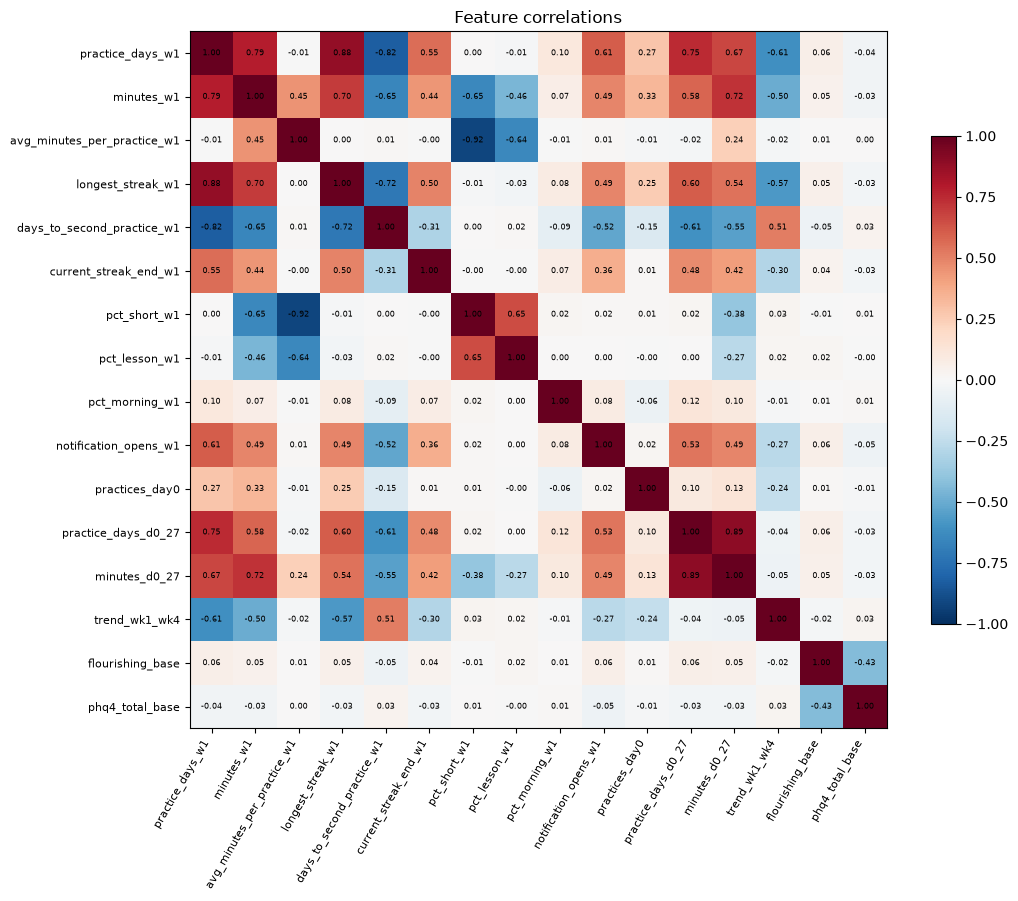

In [13]:
num = ["practice_days_w1", "minutes_w1", "avg_minutes_per_practice_w1", "longest_streak_w1", "days_to_second_practice_w1",
       "current_streak_end_w1", "pct_short_w1", "pct_lesson_w1", "pct_morning_w1", "notification_opens_w1",
       "practices_day0", "practice_days_d0_27", "minutes_d0_27", "trend_wk1_wk4", "flourishing_base", "phq4_total_base"]
corr = F[num].astype(float).corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(num))); ax.set_yticklabels(num, fontsize=8)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, shrink=.7); ax.set_title("Feature correlations"); plt.tight_layout()
plt.savefig(REPORTS / "feature_correlations.png", dpi=120); plt.show()

In [15]:
# The 10x7 vs 70x1 question: practice days and minutes are correlated, but not the same thing
print("corr(practice_days_w1, minutes_w1):", round(F.practice_days_w1.corr(F.minutes_w1), 2))
F.groupby("practice_days_w1").minutes_w1.describe()[["count", "mean", "min", "max"]].round(1)

corr(practice_days_w1, minutes_w1): 0.79


,count,mean,min,max
practice_days_w1,,,,
0,2415.0,0.0,0.0,0.0
1,5059.0,14.9,0.0,71.2
2,2857.0,29.8,0.0,120.8
3,2230.0,44.5,0.0,148.7
4,1516.0,59.1,0.0,167.6
5,687.0,76.1,0.0,172.3
6,202.0,88.4,30.2,192.6
7,34.0,104.0,37.4,215.0


---
## 4. Feature dictionary & save

In [16]:
GROUPS = {
    "A_habit_volume": ["practice_days_w1", "minutes_w1", "has_practice_w1", "avg_minutes_per_practice_w1", "had_second_practice_w1",
                       "days_to_second_practice_w1", "longest_streak_w1", "preferred_time_w1", "pct_morning_w1"],
    "C_content": [c for c in F.columns if c.startswith("pct_") and c not in ("pct_morning_w1", "pct_sessions_from_notification_w1")],
    "D_habit_cues": ["set_reminder", "reminder_slot", "notification_opens_w1", "pct_sessions_from_notification_w1",
                     "practice_near_reminder_w1", "opted_out", "opt_out_day", "opted_out_w1"],
    "E_activation": ["funnel_stage_day0", "completed_onboarding", "onboarding_seconds", "first_practice_bucket_w1",
                     "days_to_first_practice", "first_practice_observed", "first_practice_length_min", "first_practice_type",
                     "first_practice_completed", "practices_day0"],
    "F_trajectory": ["current_streak_end_w1", "late_minus_early_rate_w1", "last_active_day_w1"] +
                    [f"practice_days_wk{k}" for k in range(1, 5)] + ["trend_wk1_wk4", "practice_days_d0_27", "minutes_d0_27", "practice_days_d0_55"],
    "G_profile_wellbeing": list(prof.columns) + [c for c in F.columns if any(c.startswith(s + "_") for s in SCORES)] + ["has_base", "has_w4", "has_w8"],
    "outcomes_windows": ["obs_days", "d7_observable", "d28_observable", "retained_d7", "retained_d28",
                         "last_practice_day", "churned", "survival_days", "variant", "assignment_logged"],
}
def window(c):
    for k, v in [("_w1", "days 0-6"), ("_d0_27", "days 0-27"), ("_d0_55", "days 0-55"), ("day0", "day 0"),
                 ("_wk", "weekly"), ("_base", "baseline survey"), ("_w4", "week-4 survey"), ("_w8", "week-8 survey")]:
        if k in c: return v
    return "signup / full history"
dictionary = pd.DataFrame([dict(feature=c, group=g, window=window(c), dtype=str(F[c].dtype),
                                pct_null=round(100 * F[c].isna().mean(), 1)) for g, cols in GROUPS.items() for c in cols])
missing = set(F.columns) - set(dictionary.feature)
print("undocumented columns:", missing or "none")
dictionary.to_csv(REPORTS / "feature_dictionary.csv", index=False)

F.reset_index().to_parquet(PROC / "user_features.parquet", index=False)
print("saved user_features:", F.shape)
dictionary.groupby("group").size()

undocumented columns: none
saved user_features: (15000, 103)


group
A_habit_volume          9
C_content              12
D_habit_cues            8
E_activation           10
F_trajectory           11
G_profile_wellbeing    43
outcomes_windows       10
dtype: int64